In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, peak_widths
from google.colab import drive
from random import randint

# Montar Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
os valores dos picos são: [ 498.  605.  614.  691. 1001. 1089. 1095.]


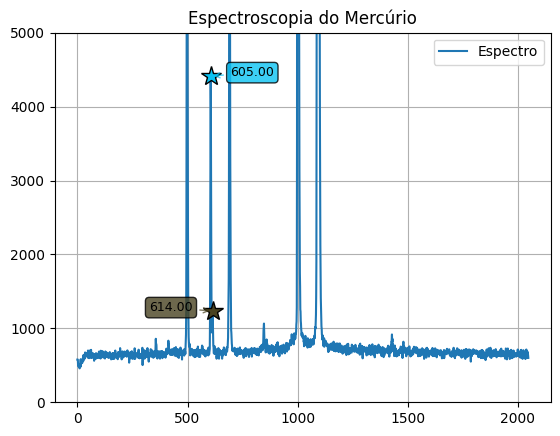

Pico em x = 498.00 ± 1.00 (FWHM = 4.92)
Pico em x = 605.00 ± 0.78 (FWHM = 3.82)
Pico em x = 614.00 ± 0.55 (FWHM = 2.71)
Pico em x = 691.00 ± 0.78 (FWHM = 3.83)
Pico em x = 1001.00 ± 0.91 (FWHM = 4.48)
Pico em x = 1089.00 ± 0.47 (FWHM = 2.29)
Pico em x = 1095.00 ± 2.26 (FWHM = 11.07)


In [ ]:
#7.2 Letra a
from numpy import loadtxt, diff, mean, append, sort
from scipy.signal import find_peaks, peak_widths
from google.colab import drive
from pylab import plot, show, grid,legend, title, text, annotate
from random import random, randint
drive.mount('/content/drive')
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Hg_2_tentantiva_SPC_COM_FENDA.txt'
data = loadtxt(url, delimiter='\t',
               converters={0: lambda x: float(x.replace(',', '.')),
                           1: lambda x: float(x.replace(',', '.'))})
x = data[:,0]
y = data[:,1]

picos, _ = find_peaks(y, height=3000)
#encontrar o pico 407
peaks, _ = find_peaks(y, height=1000)
x_limite_sup = 620
x_limite_inf = 605
picos_407 = [int(pico) for pico in peaks if x_limite_inf < x[pico] < x_limite_sup]
picos = sort(append(picos, picos_407))
peak_value = x[picos]

print(f'os valores dos picos são: {peak_value}')
cores_aleatorias = [f'#{randint(0, 0xFFFFFF):06x}' for _ in picos]
plot(x, y, label="Espectro")

for i, pico in enumerate(picos):
    # Alterna entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0
    colour = cores_aleatorias[i]

    plot(x[pico], y[pico], '*', markersize=15, color=colour, markeredgecolor='black')
    annotate(f'{x[pico]:.2f}',
                xy=(x[pico], y[pico]),
                xytext=(x_offset, y_offset),
                textcoords='offset points',
                ha='center',
                arrowprops=dict(arrowstyle='->', color=colour, lw=1, alpha=0.7),
                bbox=dict(boxstyle='round,pad=0.3', facecolor=colour, alpha=0.8),
                fontsize=9)

grid()
plt.ylim(0, 5000)
title("Espectroscopia do Mercúrio")
legend()
show()

widths, h_eval, left_ips, right_ips = peak_widths(y, picos)

for i, p in enumerate(picos):
    xc = x[p]
    fwhm = widths[i] * (x[1]-x[0])
    err_xc = fwhm /(2*6**(1/2))

    print(f"Pico em x = {xc:.2f} ± {err_xc:.2f} (FWHM = {fwhm:.2f})")

os valores dos picos são: [ 498.  605.  613.  691. 1000. 1089. 1095.]


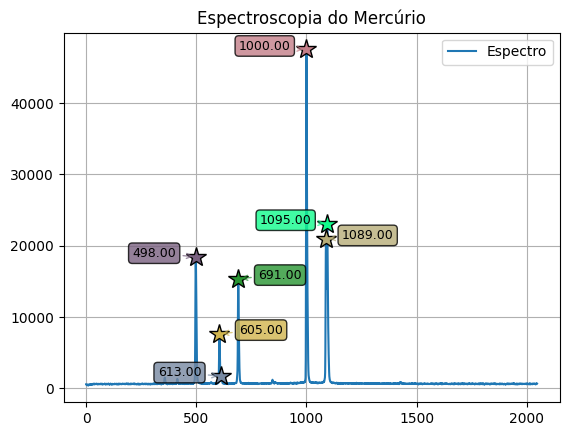

Pico em x = 498.00 ± 1.12 (FWHM = 5.48)
Pico em x = 605.00 ± 0.89 (FWHM = 4.37)
Pico em x = 613.00 ± 0.55 (FWHM = 2.69)
Pico em x = 691.00 ± 0.96 (FWHM = 4.69)
Pico em x = 1000.00 ± 0.97 (FWHM = 4.76)
Pico em x = 1089.00 ± 0.47 (FWHM = 2.32)
Pico em x = 1095.00 ± 2.20 (FWHM = 10.78)


In [ ]:
url = '/content/drive/Shareddrives/2025s2/F 740/Espect./Hg_tabdelimited.txt'
data = loadtxt(url, delimiter='\t',
               converters={0: lambda x: float(x.replace(',', '.')),
                           1: lambda x: float(x.replace(',', '.'))})
x = data[:,0]
y = data[:,1]

picos, _ = find_peaks(y, height=5000)
#encontrar o pico 407
peaks, _ = find_peaks(y, height=1000)
x_limite_sup = 620
x_limite_inf = 605
picos_407 = [int(pico) for pico in peaks if x_limite_inf < x[pico] < x_limite_sup]
picos = sort(append(picos, picos_407))
peak_value = x[picos]

cores_aleatorias = [f'#{randint(0, 0xFFFFFF):06x}' for _ in picos]
print(f'os valores dos picos são: {peak_value}')
plot(x, y, label="Espectro")
for i, pico in enumerate(picos):
    # Alterna entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0
    colour = cores_aleatorias[i]

    plot(x[pico], y[pico], '*', markersize=15, color=colour, markeredgecolor='black')
    annotate(f'{x[pico]:.2f}',
                xy=(x[pico], y[pico]),
                xytext=(x_offset, y_offset),
                textcoords='offset points',
                ha='center',
                arrowprops=dict(arrowstyle='->', color=colour, lw=1, alpha=0.7),
                bbox=dict(boxstyle='round,pad=0.3', facecolor=colour, alpha=0.8),
                fontsize=9)
grid()
title("Espectroscopia do Mercúrio")
legend()
show()

widths, h_eval, left_ips, right_ips = peak_widths(y, picos)

for i, p in enumerate(picos):
    xc = x[p]
    fwhm = widths[i] * (x[1]-x[0])
    err_xc = fwhm /(2*6**(1/2))

    print(f"Pico em x = {xc:.2f} ± {err_xc:.2f} (FWHM = {fwhm:.2f})")

os valores dos picos são: [ 614.  619.  691. 1001. 1089. 1095.]


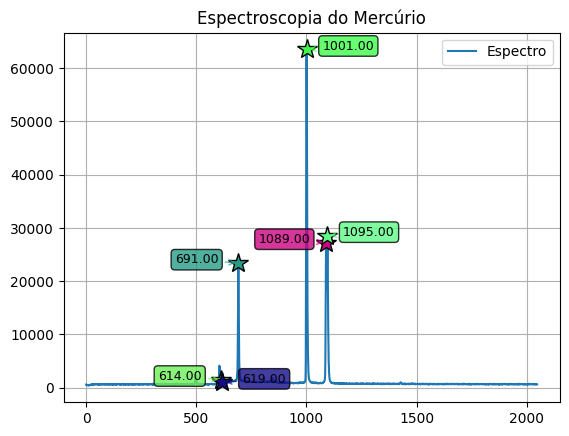

Pico em x = 614.00 ± 0.51 (FWHM = 2.49)
Pico em x = 619.00 ± 0.13 (FWHM = 0.62)
Pico em x = 691.00 ± 0.80 (FWHM = 3.94)
Pico em x = 1001.00 ± 1.01 (FWHM = 4.96)
Pico em x = 1089.00 ± 0.48 (FWHM = 2.38)
Pico em x = 1095.00 ± 2.24 (FWHM = 10.98)


In [ ]:
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Hg_tentativa_3_com_fenda.txt'
data = loadtxt(url, delimiter='\t',
               converters={0: lambda x: float(x.replace(',', '.')),
                           1: lambda x: float(x.replace(',', '.'))})
x = data[:,0]
y = data[:,1]

picos, _ = find_peaks(y, height=5000)
#encontrar o pico 407
peaks, _ = find_peaks(y, height=1000)
x_limite_sup = 620
x_limite_inf = 605
picos_407 = [int(pico) for pico in peaks if x_limite_inf < x[pico] < x_limite_sup]
picos = sort(append(picos, picos_407))
peak_value = x[picos]

print(f'os valores dos picos são: {peak_value}')
plot(x, y, label="Espectro")
cores_aleatorias = [f'#{randint(0, 0xFFFFFF):06x}' for _ in picos]

for i, pico in enumerate(picos):
    # Alterna entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0
    colour = cores_aleatorias[i]

    plot(x[pico], y[pico], '*', markersize=15, color=colour, markeredgecolor='black')
    annotate(f'{x[pico]:.2f}',
                xy=(x[pico], y[pico]),
                xytext=(x_offset, y_offset),
                textcoords='offset points',
                ha='center',
                arrowprops=dict(arrowstyle='->', color=colour, lw=1, alpha=0.7),
                bbox=dict(boxstyle='round,pad=0.3', facecolor=colour, alpha=0.8),
                fontsize=9)
grid()
title("Espectroscopia do Mercúrio")
legend()
show()

widths, h_eval, left_ips, right_ips = peak_widths(y, picos)

for i, p in enumerate(picos):
    xc = x[p]
    fwhm = widths[i] * (x[1]-x[0])
    err_xc = fwhm /(2*6**(1/2))

    print(f"Pico em x = {xc:.2f} ± {err_xc:.2f} (FWHM = {fwhm:.2f})")

os valores dos picos são: [ 498.  605.  614.  691. 1001. 1089. 1095.]


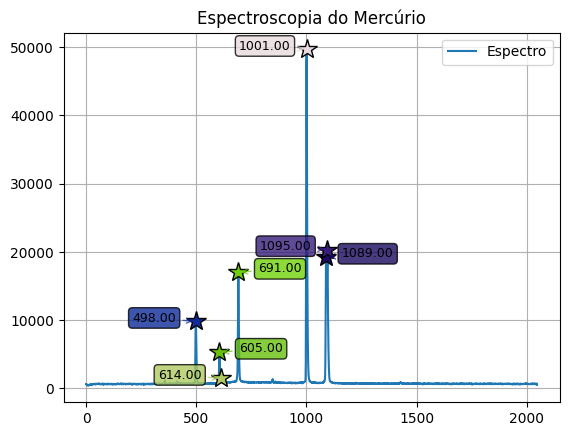

Pico em x = 498.00 ± 1.05 (FWHM = 5.16)
Pico em x = 605.00 ± 0.83 (FWHM = 4.05)
Pico em x = 614.00 ± 0.69 (FWHM = 3.40)
Pico em x = 691.00 ± 0.86 (FWHM = 4.20)
Pico em x = 1001.00 ± 0.97 (FWHM = 4.75)
Pico em x = 1089.00 ± 0.47 (FWHM = 2.30)
Pico em x = 1095.00 ± 2.25 (FWHM = 11.04)


In [ ]:
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Hg_4_tentantiva_TAB_com_fenda_Melhor_feito.txt'
data = loadtxt(url, delimiter='\t',
               converters={0: lambda x: float(x.replace(',', '.')),
                           1: lambda x: float(x.replace(',', '.'))})
x = data[:,0]
y = data[:,1]

picos, _ = find_peaks(y, height=5000)
#encontrar o pico 407
peaks, _ = find_peaks(y, height=1000)
x_limite_sup = 620
x_limite_inf = 605
picos_407 = [int(pico) for pico in peaks if x_limite_inf < x[pico] < x_limite_sup]
picos = sort(append(picos, picos_407))
peak_value = x[picos]

print(f'os valores dos picos são: {peak_value}')
plot(x, y, label="Espectro")
cores_aleatorias = [f'#{randint(0, 0xFFFFFF):06x}' for _ in picos]

for i, pico in enumerate(picos):
    # Alterna entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0
    colour = cores_aleatorias[i]

    plot(x[pico], y[pico], '*', markersize=15, color=colour, markeredgecolor='black')
    annotate(f'{x[pico]:.2f}',
                xy=(x[pico], y[pico]),
                xytext=(x_offset, y_offset),
                textcoords='offset points',
                ha='center',
                arrowprops=dict(arrowstyle='->', color=colour, lw=1, alpha=0.7),
                bbox=dict(boxstyle='round,pad=0.3', facecolor=colour, alpha=0.8),
                fontsize=9)
grid()
title("Espectroscopia do Mercúrio")
legend()
show()

widths, h_eval, left_ips, right_ips = peak_widths(y, picos)

for i, p in enumerate(picos):
    xc = x[p]
    fwhm = widths[i] * (x[1]-x[0])
    err_xc = fwhm /(2*6**(1/2))

    print(f"Pico em x = {xc:.2f} ± {err_xc:.2f} (FWHM = {fwhm:.2f})")

os valores dos picos são: [1444. 1447. 1475. 1479. 1500. 1502. 1538. 1573. 1577. 1610. 1613. 1651.
 1656. 1664. 1678. 1716. 1749. 1756. 1771. 1775. 1803. 1808. 1818. 1845.
 1851. 1857. 1859. 1903. 1907. 1935. 1939. 1943. 1945. 1984. 1986. 1994.]


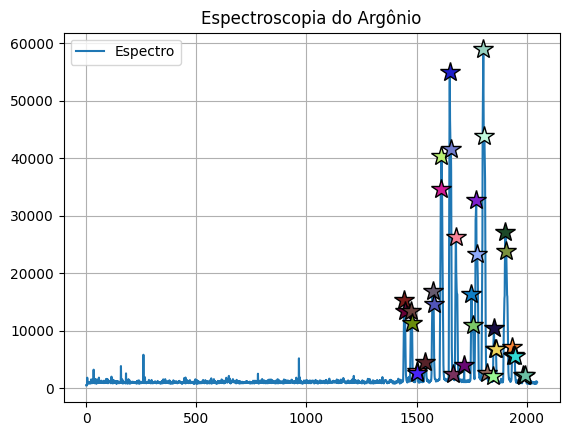

Pico em x = 1444.00 ± 1.65 (FWHM = 8.10)
Pico em x = 1447.00 ± 0.30 (FWHM = 1.45)
Pico em x = 1475.00 ± 1.70 (FWHM = 8.31)
Pico em x = 1479.00 ± 0.17 (FWHM = 0.82)
Pico em x = 1500.00 ± 1.58 (FWHM = 7.73)
Pico em x = 1502.00 ± 0.19 (FWHM = 0.94)
Pico em x = 1538.00 ± 1.95 (FWHM = 9.55)
Pico em x = 1573.00 ± 1.91 (FWHM = 9.36)
Pico em x = 1577.00 ± 0.21 (FWHM = 1.04)
Pico em x = 1610.00 ± 0.11 (FWHM = 0.53)
Pico em x = 1613.00 ± 2.02 (FWHM = 9.92)
Pico em x = 1651.00 ± 2.04 (FWHM = 10.02)
Pico em x = 1656.00 ± 0.11 (FWHM = 0.54)
Pico em x = 1664.00 ± 0.13 (FWHM = 0.65)
Pico em x = 1678.00 ± 2.02 (FWHM = 9.89)
Pico em x = 1716.00 ± 0.22 (FWHM = 1.09)
Pico em x = 1749.00 ± 2.22 (FWHM = 10.90)
Pico em x = 1756.00 ± 0.53 (FWHM = 2.61)
Pico em x = 1771.00 ± 2.38 (FWHM = 11.64)
Pico em x = 1775.00 ± 0.20 (FWHM = 1.00)
Pico em x = 1803.00 ± 2.56 (FWHM = 12.55)
Pico em x = 1808.00 ± 0.34 (FWHM = 1.67)
Pico em x = 1818.00 ± 0.11 (FWHM = 0.54)
Pico em x = 1845.00 ± 0.19 (FWHM = 0.91)
Pico em x = 

In [ ]:
url = '/content/drive/MyDrive/2025s2/F 740/Espect./argonio.txt'
data = loadtxt(url, delimiter='\t',
               converters={0: lambda x: float(x.replace(',', '.')),
                           1: lambda x: float(x.replace(',', '.'))})
x = data[:,0]
y = data[:,1]

picos, _ = find_peaks(y, height=2000)
#Filtro
x_limite = 1400.0
picos = [pico for pico in picos if x[pico] > x_limite]
peak_value = x[picos]

print(f'os valores dos picos são: {peak_value}')

plot(x, y, label="Espectro")
cores_aleatorias = [f'#{randint(0, 0xFFFFFF):06x}' for _ in picos]

for i, pico in enumerate(picos):
    # Alterna entre esquerda e direita
    x_offset = 30 if i % 2 == 0 else -30
    y_offset = 0
    colour = cores_aleatorias[i]

    plot(x[pico], y[pico], '*', markersize=15, color=colour, markeredgecolor='black')
    # annotate(f'{x[pico]:.2f}',
    #             xy=(x[pico], y[pico]),
    #             xytext=(x_offset, y_offset),
    #             textcoords='offset points',
    #             ha='center',
    #             arrowprops=dict(arrowstyle='->', color=colour, lw=1, alpha=0.7),
    #             bbox=dict(boxstyle='round,pad=0.3', facecolor=colour, alpha=0.8),
    #             fontsize=9)
grid()
title("Espectroscopia do Argônio")
legend()
show()

widths, h_eval, left_ips, right_ips = peak_widths(y, picos)

for i, p in enumerate(picos):
    xc = x[p]
    fwhm = widths[i] * (x[1]-x[0])
    err_xc = fwhm /(2*6**(1/2))

    print(f"Pico em x = {xc:.2f} ± {err_xc:.2f} (FWHM = {fwhm:.2f})")

#[1444, 1475, 1500, 1538, 1573, 1613, 1651,1678, 1716, 1749, 1771, 1845,
#1851, 1857, 1903, 1935, 1945, 1994]


os valores dos picos são: [1444. 1475. 1572. 1612. 1650. 1678. 1749. 1770. 1803. 1851. 1899. 1903.]


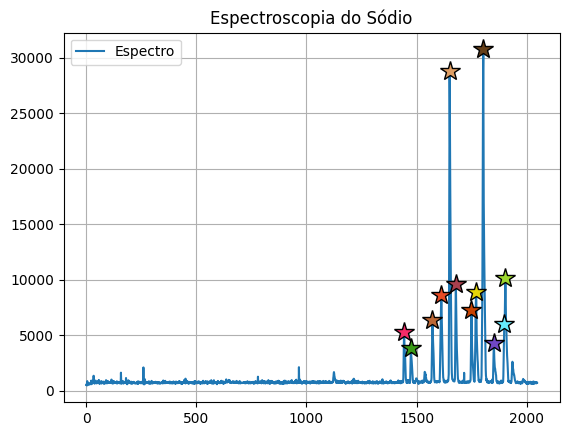

In [ ]:
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Sódio_1_tentantiva.txt'
data = loadtxt(url, delimiter='\t',
               converters={0: lambda x: float(x.replace(',', '.')),
                           1: lambda x: float(x.replace(',', '.'))})
x = data[:,0]
y = data[:,1]

picos, _ = find_peaks(y, height=3000)
peak_value = x[picos]

print(f'os valores dos picos são: {peak_value}')
plot(x, y, label="Espectro")
cores_aleatorias = [f'#{randint(0, 0xFFFFFF):06x}' for _ in picos]

for i, pico in enumerate(picos):
    # Alterna entre esquerda e direita
    x_offset = randint(-100, 100)
    y_offset = randint(0, 100)
    colour = cores_aleatorias[i]

    plot(x[pico], y[pico], '*', markersize=15, color=colour, markeredgecolor='black')
    # annotate(f'{x[pico]:.2f}',
    #             xy=(x[pico], y[pico]),
    #             xytext=(x_offset, y_offset),
    #             textcoords='offset points',
    #             ha='center',
    #             arrowprops=dict(arrowstyle='->', color=colour, lw=1, alpha=0.7),
    #             bbox=dict(boxstyle='round,pad=0.3', facecolor=colour, alpha=0.8),
    #             fontsize=9)
grid()
title("Espectroscopia do Sódio")
legend()
show()

os valores dos picos são: [1475. 1573. 1612. 1650. 1678. 1749. 1770. 1775. 1778. 1802. 1851. 1899.
 1903. 1907. 1935.]


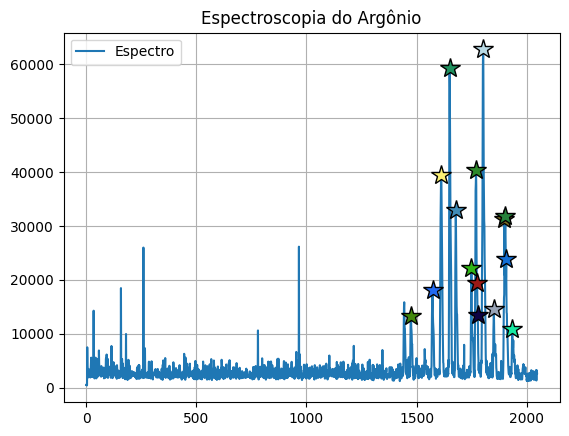

In [ ]:
url = '/content/drive/MyDrive/2025s2/F 740/Espect./argonio_com_fenda.txt'
data = loadtxt(url, delimiter='\t',
               converters={0: lambda x: float(x.replace(',', '.')),
                           1: lambda x: float(x.replace(',', '.'))})
x = data[:,0]
y = data[:,1]

picos, _ = find_peaks(y, height=10000)
#Filtro
x_limite = 1450.0
picos = [pico for pico in picos if x[pico] > x_limite]
peak_value = x[picos]

print(f'os valores dos picos são: {peak_value}')
plot(x, y, label="Espectro")
cores_aleatorias = [f'#{randint(0, 0xFFFFFF):06x}' for _ in picos]

for i, pico in enumerate(picos):
    # Alterna entre esquerda e direita
    x_offset = 30 if i % 2 == 0 else -30
    y_offset = 30 if i % 2 == 0 else -30
    colour = cores_aleatorias[i]

    plot(x[pico], y[pico], '*', markersize=15, color=colour, markeredgecolor='black')
    # annotate(f'{x[pico]:.2f}',
    #             xy=(x[pico], y[pico]),
    #             xytext=(x_offset, y_offset),
    #             textcoords='offset points',
    #             ha='center',
    #             arrowprops=dict(arrowstyle='->', color=colour, lw=1, alpha=0.7),
    #             bbox=dict(boxstyle='round,pad=0.3', facecolor=colour, alpha=0.8),
    #             fontsize=9)
grid()
title("Espectroscopia do Argônio")
legend()
show()

os valores dos picos são: [1444. 1474. 1499. 1538. 1572. 1612. 1650. 1678. 1749. 1770. 1802. 1851.
 1898. 1903. 1935. 1940. 1944. 1984. 1988. 1993.]


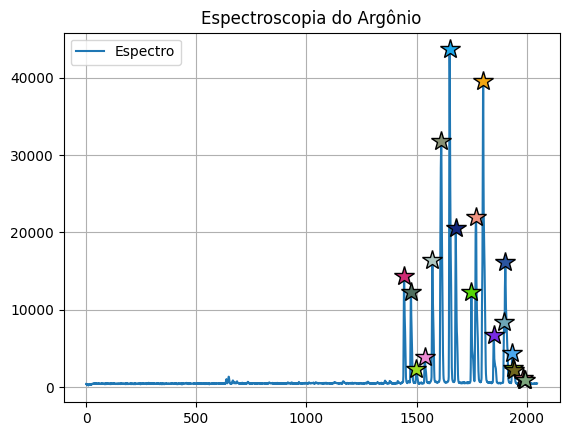

In [ ]:
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Argonio_2_tentativa_com_fenda.txt'
data = loadtxt(url, delimiter='\t',
               converters={0: lambda x: float(x.replace(',', '.')),
                           1: lambda x: float(x.replace(',', '.'))})
x = data[:,0]
y = data[:,1]

picos, _ = find_peaks(y, height=900)
#Filtro
x_limite = 1300
picos = [pico for pico in picos if x[pico] > x_limite]
peak_value = x[picos]

print(f'os valores dos picos são: {peak_value}')
plot(x, y, label="Espectro")
cores_aleatorias = [f'#{randint(0, 0xFFFFFF):06x}' for _ in picos]

for i, pico in enumerate(picos):
    # Alterna entre esquerda e direita
    x_offset = 30 if i % 2 == 0 else -30
    y_offset = 30 if i % 2 == 0 else -30
    colour = cores_aleatorias[i]

    plot(x[pico], y[pico], '*', markersize=15, color=colour, markeredgecolor='black')
    # annotate(f'{x[pico]:.2f}',
    #             xy=(x[pico], y[pico]),
    #             xytext=(x_offset, y_offset),
    #             textcoords='offset points',
    #             ha='center',
    #             arrowprops=dict(arrowstyle='->', color=colour, lw=1, alpha=0.7),
    #             bbox=dict(boxstyle='round,pad=0.3', facecolor=colour, alpha=0.8),
    #             fontsize=9)
grid()
title("Espectroscopia do Argônio")
legend()
show()
lista = [1444, 1474, 1499, 1538, 1572, 1612, 1650, 1678, 1749, 1770, 1802, 1851,
 1898, 1903, 1935, 1944, 1984, 1993]

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

true_wavelengths = [365.015, 404.656, 407.783, 435.833, 546.074, 576.96, 579.066,
                    696.543, 706.722, 714.704, 727.294, 738.398, 750.387, 763.511,
                    772.376, 794.818, 800.616, 811.531, 826.452, 840.820, 842.465,
                    852.144, 866.794, 912.297, 922.450]

pixels = [498,  605,  614,  691, 1001, 1089, 1095, 1444, 1474, 1499, 1538, 1572,
          1612, 1650, 1678, 1749, 1770, 1802, 1851, 1898, 1903, 1935, 1944, 1984, 1993]

X = np.column_stack([pixels,
                     [p**2 for p in pixels],
                     [p**3 for p in pixels]])

#Adicionar coluna de 1s para o intercepto
X = np.column_stack([np.ones(len(pixels)), X])

#X * coeficientes = true_wavelengths
coeficientes = np.linalg.lstsq(X, true_wavelengths, rcond=None)[0]

print("Coeficientes da calibração:")
print(f"Intercept (C0): {coeficientes[0]:.6f}")
print(f"Coeficiente 1 (C1): {coeficientes[1]:.8f}")
print(f"Coeficiente 2 (C2): {coeficientes[2]:.10E}")
print(f"Coeficiente 3 (C3): {coeficientes[3]:.10E}")

# Calcular R²
y_pred = X @ coeficientes
ss_res = np.sum((true_wavelengths - y_pred) ** 2)
ss_tot = np.sum((true_wavelengths - np.mean(true_wavelengths)) ** 2)
r_squared = 1 - (ss_res / ss_tot)

print(f"\nR²: {r_squared:.9f}")

plt.figure(figsize=(10,5))
plt.plot(pixels_cont, y_fit, 'r-', label='Polinômio ajustado (grau 3)')
plt.plot(pixels, true_wavelengths, 'bo', label='Pontos medidos')
plt.xlabel('Pixel')
plt.ylabel('Comprimento de onda (nm)')
plt.title('Calibração do Espectrômetro')
plt.legend()
plt.grid(True)
plt.show()

Coeficientes da calibração:
Intercept (C0): 80.852017
Coeficiente 1 (C1): 0.68746024
Coeficiente 2 (C2): -2.9707903323E-04
Coeficiente 3 (C3): 7.8859072494E-08

R²: 0.996479211


NameError: name 'y_fit' is not defined

<Figure size 1000x500 with 0 Axes>

Coeficientes da calibração:
Intercept (C0): 167.852615
Coeficiente 1 (C1): 0.42343231
Coeficiente 2 (C2): -6.4830197820E-05
Coeficiente 3 (C3): 1.9261458262E-08


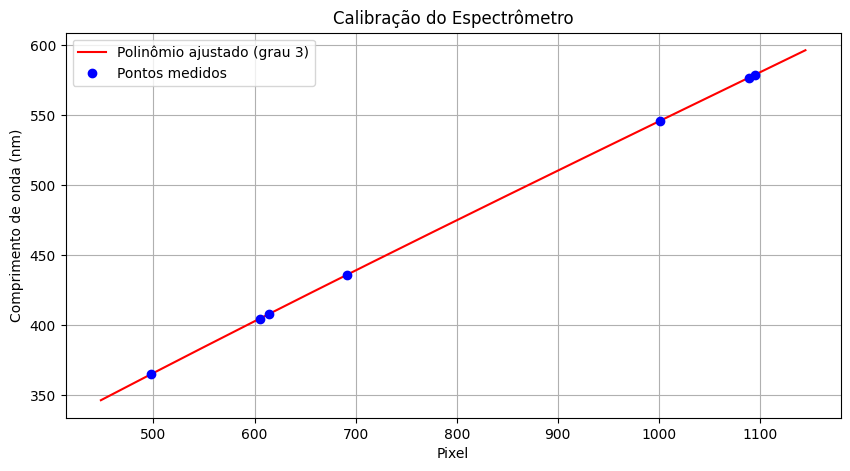


R²: 0.999999714


In [ ]:

#################################################################################
####Esse código é só com os dados do Mercúrio, o R^2 foi quase perfeito
################################################################################


import numpy as np

true_wavelengths = [365.015, 404.656, 407.783, 435.833, 546.074, 576.96, 579.066]

pixels = [498,  605,  614,  691, 1001, 1089, 1095,]

X = np.column_stack([pixels,
                     [p**2 for p in pixels],
                     [p**3 for p in pixels]])

#Adicionar coluna de 1s para o intercepto
X = np.column_stack([np.ones(len(pixels)), X])

#X * coeficientes = true_wavelengths
coeficientes = np.linalg.lstsq(X, true_wavelengths, rcond=None)[0]

print("Coeficientes da calibração:")
print(f"Intercept (C0): {coeficientes[0]:.6f}")
print(f"Coeficiente 1 (C1): {coeficientes[1]:.8f}")
print(f"Coeficiente 2 (C2): {coeficientes[2]:.10E}")
print(f"Coeficiente 3 (C3): {coeficientes[3]:.10E}")

# Calcular R²
y_pred = X @ coeficientes
ss_res = np.sum((true_wavelengths - y_pred) ** 2)
ss_tot = np.sum((true_wavelengths - np.mean(true_wavelengths)) ** 2)
r_squared = 1 - (ss_res / ss_tot)

pixels_cont = np.linspace(min(pixels)-50, max(pixels)+50, 500)
y_fit = coeficientes[0] + coeficientes[1]*pixels_cont + coeficientes[2]*pixels_cont**2 + coeficientes[3]*pixels_cont**3


plt.figure(figsize=(10,5))
plt.plot(pixels_cont, y_fit, 'r-', label='Polinômio ajustado (grau 3)')
plt.plot(pixels, true_wavelengths, 'bo', label='Pontos medidos')
plt.xlabel('Pixel')
plt.ylabel('Comprimento de onda (nm)')
plt.title('Calibração do Espectrômetro')
plt.legend()
plt.grid(True)
plt.show()
print(f"\nR²: {r_squared:.9f}")

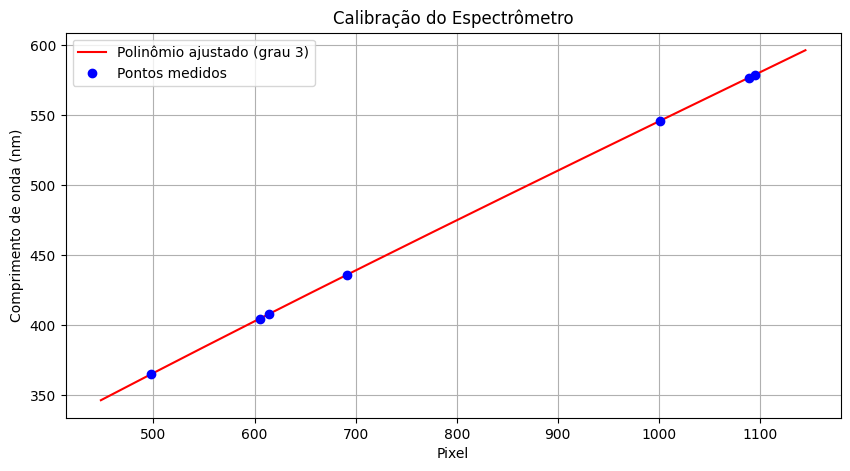

In [ ]:
########Pra ver o fit#########
import numpy as np
import matplotlib.pyplot as plt

true_wavelengths = [365.015, 404.656, 407.783, 435.833, 546.074, 576.96, 579.066]
pixels = [498,  605,  614,  691, 1001, 1089, 1095]

X = np.column_stack([np.ones(len(pixels)),
                     pixels,
                     [p**2 for p in pixels],
                     [p**3 for p in pixels]])


coeficientes = np.linalg.lstsq(X, true_wavelengths, rcond=None)[0]


pixels_cont = np.linspace(min(pixels)-50, max(pixels)+50, 500)
y_fit = coeficientes[0] + coeficientes[1]*pixels_cont + coeficientes[2]*pixels_cont**2 + coeficientes[3]*pixels_cont**3


plt.figure(figsize=(10,5))
plt.plot(pixels_cont, y_fit, 'r-', label='Polinômio ajustado (grau 3)')
plt.plot(pixels, true_wavelengths, 'bo', label='Pontos medidos')
plt.xlabel('Pixel')
plt.ylabel('Comprimento de onda (nm)')
plt.title('Calibração do Espectrômetro')
plt.legend()
plt.grid(True)
plt.show()



Coeficientes ajustados (±1σ):
C0 = 1.7513488027e+02 ± 4.6893820233e+00
C1 = 3.9124004908e-01 ± 1.3193062118e-02
C2 = -1.9386143793e-05 ± 1.1244854894e-05
C3 = -9.9746416912e-10 ± 2.9814093388e-09

Pixel   λ(p) [nm]       σλ(p) [nm]
--------------------------------------
  500     365.7837   ±    0.6618
  800     475.2091   ±    0.3936
 1000     545.9913   ±    0.4051
 1500     715.0097   ±    0.3391
 1800     810.7387   ±    0.2986
 2000     872.0907   ±    0.6835


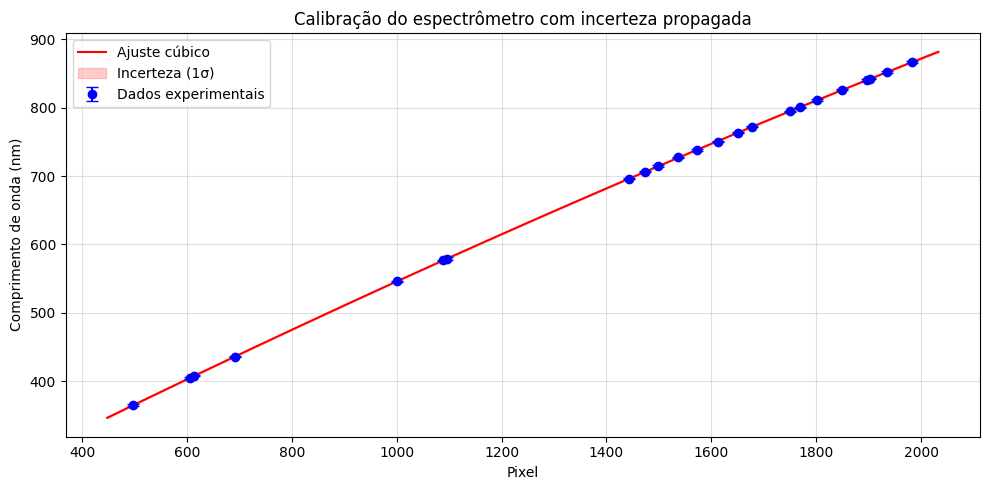

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- Dados ---
pixels = np.array([498, 605, 614, 691, 1001, 1089, 1095, 1443, 1474, 1499, 1537, 1572,
                   1612, 1650, 1678, 1749, 1769, 1802, 1850, 1897, 1902, 1934, 1983])
true_wavelengths = np.array([365.015, 404.656, 407.783, 435.833, 546.074, 576.96, 579.066,
                             696.543, 706.722, 714.704, 727.294, 738.398, 750.387, 763.511,
                             772.376, 794.818, 800.616, 811.531, 826.452, 840.820, 842.465,
                             852.144, 866.749])
err = np.array([1.05, 0.83, 0.69, 0.86, 0.97, 0.47, 2.25, 1.05, 1.05, 1.05, 1.05, 1.05,
                1.05, 1.05, 1.05, 1.05, 1.05, 1.05, 1.05, 1.05, 1.05, 1.05, 1.05])

# --- Função polinomial de grau 3 ---
def poly3(x, c0, c1, c2, c3):
    return c0 + c1*x + c2*x**2 + c3*x**3

# --- Ajuste ponderado ---
popt, pcov = curve_fit(poly3, pixels, true_wavelengths, sigma=err, absolute_sigma=True)

# --- Coeficientes e incertezas ---
print("Coeficientes ajustados (±1σ):")
for i, (c, var) in enumerate(zip(popt, np.diag(pcov))):
    print(f"C{i} = {c:.10e} ± {np.sqrt(var):.10e}")

# --- Função de incerteza propagada ---
def lambda_uncertainty(x, popt, pcov):
    g = np.array([1, x, x**2, x**3])
    return np.sqrt(g @ pcov @ g)

# --- Imprimir lambda e erro de lambda para alguns pixels ---
print("\nPixel   λ(p) [nm]       σλ(p) [nm]")
print("--------------------------------------")
for p in [500, 800, 1000, 1500, 1800, 2000]:
    lam = poly3(p, *popt)
    sigma_lam = lambda_uncertainty(p, popt, pcov)
    print(f"{p:5d}   {lam:10.4f}   ±{sigma_lam:10.4f}")

# --- (opcional) gráfico com incerteza propagada ---
pixels_cont = np.linspace(min(pixels)-50, max(pixels)+50, 500)
y_fit = poly3(pixels_cont, *popt)
sigma_fit = np.array([lambda_uncertainty(x, popt, pcov) for x in pixels_cont])

plt.figure(figsize=(10, 5))
plt.plot(pixels_cont, y_fit, 'r-', label='Ajuste cúbico')
plt.fill_between(pixels_cont, y_fit - sigma_fit, y_fit + sigma_fit, color='r', alpha=0.2, label='Incerteza (1σ)')
plt.errorbar(pixels, true_wavelengths, yerr=err, fmt='bo', capsize=4, label='Dados experimentais')
plt.xlabel('Pixel')
plt.ylabel('Comprimento de onda (nm)')
plt.title('Calibração do espectrômetro com incerteza propagada')
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


Coeficientes da calibração:
Intercept (C0): 174.641721
Coeficiente 1 (C1): 0.39284702
Coeficiente 2 (C2): -2.0953376575E-05
Coeficiente 3 (C3): -5.5335225291E-10

R²: 0.999997268


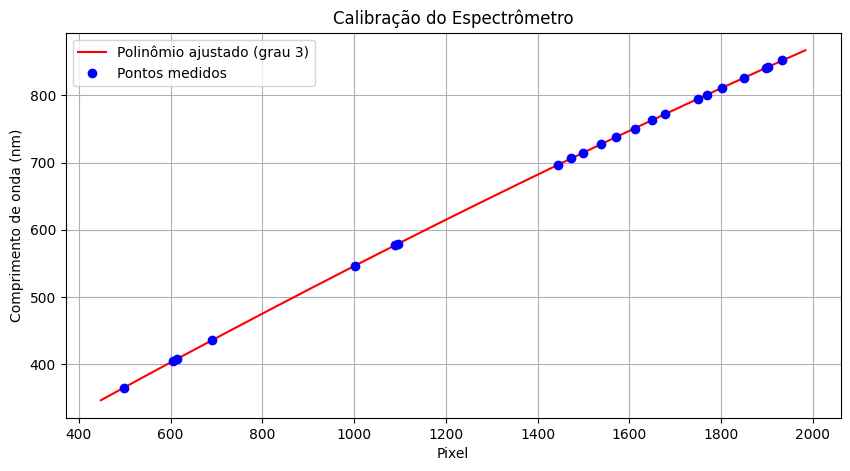

In [ ]:

#################################################################################
#### código com Ar e Hg dia 2
################################################################################
import numpy as np
import matplotlib.pyplot as plt

true_wavelengths = [365.015, 404.656, 407.783, 435.833, 546.074, 576.96, 579.066,
                    696.543, 706.722, 714.704, 727.294, 738.398, 750.387, 763.511,
                    772.376, 794.818, 800.616, 811.531, 826.452, 840.820, 842.465,
                    852.144]

pixels = [498,  605,  614,  691, 1001, 1089, 1095, 1444, 1474, 1499, 1538, 1572,
          1612, 1650, 1678, 1749, 1770, 1802, 1851, 1897, 1903, 1934]

X = np.column_stack([pixels,
                     [p**2 for p in pixels],
                     [p**3 for p in pixels]])

#Adicionar coluna de 1s para o intercepto
X = np.column_stack([np.ones(len(pixels)), X])

#X * coeficientes = true_wavelengths
coeficientes = np.linalg.lstsq(X, true_wavelengths, rcond=None)[0]

print("Coeficientes da calibração:")
print(f"Intercept (C0): {coeficientes[0]:.6f}")
print(f"Coeficiente 1 (C1): {coeficientes[1]:.8f}")
print(f"Coeficiente 2 (C2): {coeficientes[2]:.10E}")
print(f"Coeficiente 3 (C3): {coeficientes[3]:.10E}")

# Calcular R²
y_pred = X @ coeficientes
ss_res = np.sum((true_wavelengths - y_pred) ** 2)
ss_tot = np.sum((true_wavelengths - np.mean(true_wavelengths)) ** 2)
r_squared = 1 - (ss_res / ss_tot)
print(f"\nR²: {r_squared:.9f}")

pixels_cont = np.linspace(min(pixels)-50, max(pixels)+50, 500)
y_fit = coeficientes[0] + coeficientes[1]*pixels_cont + coeficientes[2]*pixels_cont**2 + coeficientes[3]*pixels_cont**3


plt.figure(figsize=(10,5))
plt.plot(pixels_cont, y_fit, 'r-', label='Polinômio ajustado (grau 3)')
plt.plot(pixels, true_wavelengths, 'bo', label='Pontos medidos')
plt.xlabel('Pixel')
plt.ylabel('Comprimento de onda (nm)')
plt.title('Calibração do Espectrômetro')
plt.legend()
plt.grid(True)
plt.show()

Coeficientes da calibração:
Intercept (C0): 174.641721
Coeficiente 1 (C1): 0.39284702
Coeficiente 2 (C2): -2.0953376575E-05
Coeficiente 3 (C3): -5.5335225291E-10

R²: 0.999997268


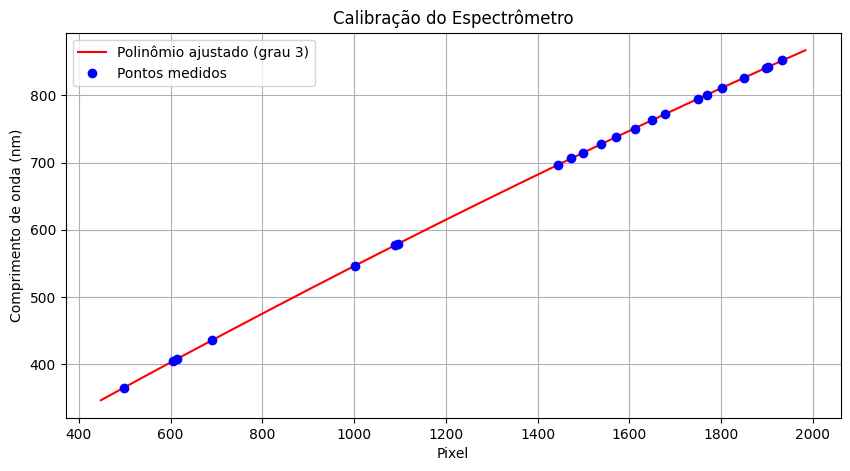

In [ ]:

#################################################################################
#### código com Ar e Hg dia 2
################################################################################
import numpy as np
import matplotlib.pyplot as plt

true_wavelengths = [365.015, 404.656, 407.783, 435.833, 546.074, 576.96, 579.066,
                    696.543, 706.722, 714.704, 727.294, 738.398, 750.387, 763.511,
                    772.376, 794.818, 800.616, 811.531, 826.452, 840.820, 842.465,
                    852.144]

pixels = [498,  605,  614,  691, 1001, 1089, 1095, 1444, 1474, 1499, 1538, 1572,
          1612, 1650, 1678, 1749, 1770, 1802, 1851, 1897, 1903, 1934]

X = np.column_stack([pixels,
                     [p**2 for p in pixels],
                     [p**3 for p in pixels]])

#Adicionar coluna de 1s para o intercepto
X = np.column_stack([np.ones(len(pixels)), X])

#X * coeficientes = true_wavelengths
coeficientes = np.linalg.lstsq(X, true_wavelengths, rcond=None)[0]

print("Coeficientes da calibração:")
print(f"Intercept (C0): {coeficientes[0]:.6f}")
print(f"Coeficiente 1 (C1): {coeficientes[1]:.8f}")
print(f"Coeficiente 2 (C2): {coeficientes[2]:.10E}")
print(f"Coeficiente 3 (C3): {coeficientes[3]:.10E}")

# Calcular R²
y_pred = X @ coeficientes
ss_res = np.sum((true_wavelengths - y_pred) ** 2)
ss_tot = np.sum((true_wavelengths - np.mean(true_wavelengths)) ** 2)
r_squared = 1 - (ss_res / ss_tot)
print(f"\nR²: {r_squared:.9f}")

pixels_cont = np.linspace(min(pixels)-50, max(pixels)+50, 500)
y_fit = coeficientes[0] + coeficientes[1]*pixels_cont + coeficientes[2]*pixels_cont**2 + coeficientes[3]*pixels_cont**3


plt.figure(figsize=(10,5))
plt.plot(pixels_cont, y_fit, 'r-', label='Polinômio ajustado (grau 3)')
plt.plot(pixels, true_wavelengths, 'bo', label='Pontos medidos')
plt.xlabel('Pixel')
plt.ylabel('Comprimento de onda (nm)')
plt.title('Calibração do Espectrômetro')
plt.legend()
plt.grid(True)
plt.show()

os valores dos picos são: [696.56 706.73 714.57 727.26 738.59 751.47 763.63 772.54 794.99 801.58
 811.59 826.81 842.84 852.64 853.25 867.55 868.77 869.37]


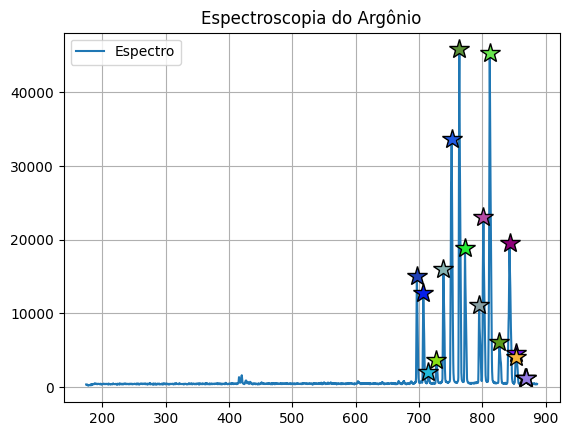

In [ ]:
url = '/content/drive/MyDrive/2025s2/F 740/Espect./AR_LAMBDA1.txt'
data = loadtxt(url, delimiter='\t',
               converters={0: lambda x: float(x.replace(',', '.')),
                           1: lambda x: float(x.replace(',', '.'))})
x = data[:,0]
y = data[:,1]

picos, _ = find_peaks(y, height=900)
#Filtro
x_limite = 600
picos = [pico for pico in picos if x[pico] > x_limite]
peak_value = x[picos]

print(f'os valores dos picos são: {peak_value}')
plot(x, y, label="Espectro")
cores_aleatorias = [f'#{randint(0, 0xFFFFFF):06x}' for _ in picos]

for i, pico in enumerate(picos):
    # Alterna entre esquerda e direita
    x_offset = 30 if i % 2 == 0 else -30
    y_offset = 30 if i % 2 == 0 else -30
    colour = cores_aleatorias[i]

    plot(x[pico], y[pico], '*', markersize=15, color=colour, markeredgecolor='black')
    # annotate(f'{x[pico]:.2f}',
    #             xy=(x[pico], y[pico]),
    #             xytext=(x_offset, y_offset),
    #             textcoords='offset points',
    #             ha='center',
    #             arrowprops=dict(arrowstyle='->', color=colour, lw=1, alpha=0.7),
    #             bbox=dict(boxstyle='round,pad=0.3', facecolor=colour, alpha=0.8),
    #             fontsize=9)
grid()
title("Espectroscopia do Argônio")
legend()
show()
lista = [1444, 1474, 1499, 1538, 1572, 1612, 1650, 1678, 1749, 1770, 1802, 1851,
 1898, 1903, 1935, 1944, 1984, 1993]

os valores dos picos são: [1443. 1474. 1499. 1537. 1572. 1612. 1650. 1678. 1749. 1769. 1802. 1850.
 1897. 1902. 1934. 1983.]


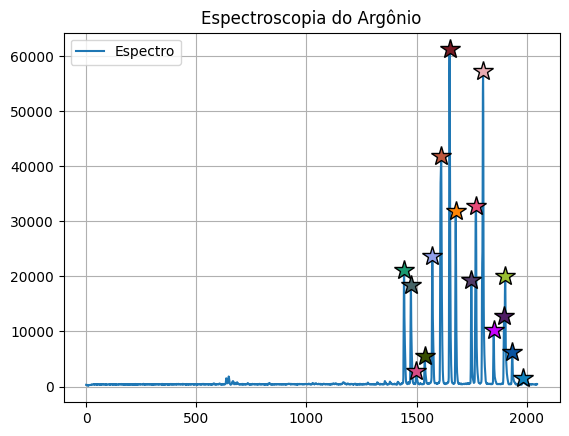

In [ ]:
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Argonio_3_com_fenda'
data = loadtxt(url, delimiter='\t',
               converters={0: lambda x: float(x.replace(',', '.')),
                           1: lambda x: float(x.replace(',', '.'))})
x = data[:,0]
y = data[:,1]

picos, _ = find_peaks(y, height=900)
#Filtro
x_limite = 1400
picos = [pico for pico in picos if x[pico] > x_limite]
peak_value = x[picos]

print(f'os valores dos picos são: {peak_value}')
plot(x, y, label="Espectro")
cores_aleatorias = [f'#{randint(0, 0xFFFFFF):06x}' for _ in picos]

for i, pico in enumerate(picos):
    # Alterna entre esquerda e direita
    x_offset = 30 if i % 2 == 0 else -30
    y_offset = 30 if i % 2 == 0 else -30
    colour = cores_aleatorias[i]

    plot(x[pico], y[pico], '*', markersize=15, color=colour, markeredgecolor='black')
    # annotate(f'{x[pico]:.2f}',
    #             xy=(x[pico], y[pico]),
    #             xytext=(x_offset, y_offset),
    #             textcoords='offset points',
    #             ha='center',
    #             arrowprops=dict(arrowstyle='->', color=colour, lw=1, alpha=0.7),
    #             bbox=dict(boxstyle='round,pad=0.3', facecolor=colour, alpha=0.8),
    #             fontsize=9)
grid()
title("Espectroscopia do Argônio")
legend()
show()
lista = [1443, 1474, 1499, 1537, 1572, 1612, 1650, 1678, 1749, 1769, 1802, 1850,
 1897, 1902, 1934, 1983]

Coeficientes da calibração:
Intercept (C0): 175.197815
Coeficiente 1 (C1): 0.39105137
Coeficiente 2 (C2): -1.9238977154E-05
Coeficiente 3 (C3): -1.0316606458E-09

R²: 0.999997548


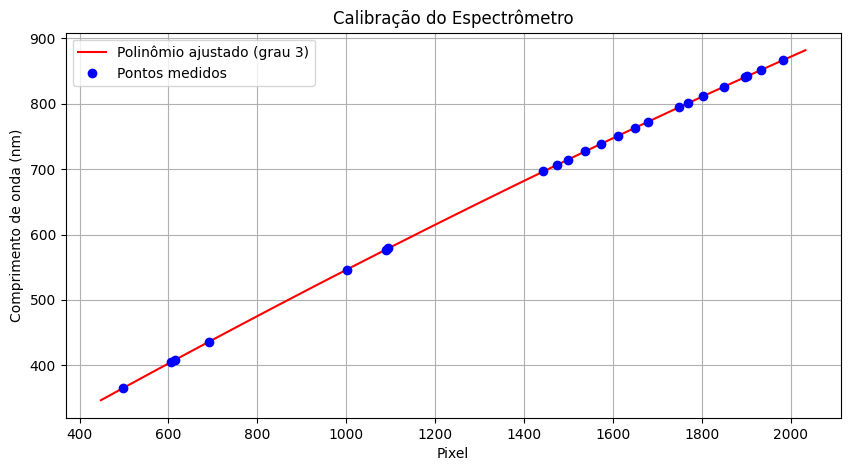

In [ ]:

#################################################################################
#### código com Ar e Hg dia 2 e 3o teste com o Ar.
################################################################################
import numpy as np
import matplotlib.pyplot as plt

true_wavelengths = [365.015, 404.656, 407.783, 435.833, 546.074, 576.96, 579.066,
                    696.543, 706.722, 714.704, 727.294, 738.398, 750.387, 763.511,
                    772.376, 794.818, 800.616, 811.531, 826.452, 840.820, 842.465,
                    852.144, 866.749]

pixels = [498,  605,  614,  691, 1001, 1089, 1095, 1443, 1474, 1499, 1537, 1572, 1612, 1650, 1678, 1749, 1769, 1802, 1850,
 1897, 1902, 1934, 1983]

X = np.column_stack([pixels,
                     [p**2 for p in pixels],
                     [p**3 for p in pixels]])

#Adicionar coluna de 1s para o intercepto
X = np.column_stack([np.ones(len(pixels)), X])

#X * coeficientes = true_wavelengths
coeficientes = np.linalg.lstsq(X, true_wavelengths, rcond=None)[0]

print("Coeficientes da calibração:")
print(f"Intercept (C0): {coeficientes[0]:.6f}")
print(f"Coeficiente 1 (C1): {coeficientes[1]:.8f}")
print(f"Coeficiente 2 (C2): {coeficientes[2]:.10E}")
print(f"Coeficiente 3 (C3): {coeficientes[3]:.10E}")

# Calcular R²
y_pred = X @ coeficientes
ss_res = np.sum((true_wavelengths - y_pred) ** 2)
ss_tot = np.sum((true_wavelengths - np.mean(true_wavelengths)) ** 2)
r_squared = 1 - (ss_res / ss_tot)
print(f"\nR²: {r_squared:.9f}")

pixels_cont = np.linspace(min(pixels)-50, max(pixels)+50, 500)
y_fit = coeficientes[0] + coeficientes[1]*pixels_cont + coeficientes[2]*pixels_cont**2 + coeficientes[3]*pixels_cont**3


plt.figure(figsize=(10,5))
plt.plot(pixels_cont, y_fit, 'r-', label='Polinômio ajustado (grau 3)')
plt.plot(pixels, true_wavelengths, 'bo', label='Pontos medidos')
plt.xlabel('Pixel')
plt.ylabel('Comprimento de onda (nm)')
plt.title('Calibração do Espectrômetro')
plt.legend()
plt.grid(True)
plt.show()